In [1]:
%load_ext autoreload
%autoreload 2

In [21]:
import sys
import os

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
from dask.diagnostics import ProgressBar
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.data_processing.load_data import ClimateModelData
from cordex2energy.utils.constants import EXTENT_CH, EXTENT_BC_MRRO, EXTENT_BC
from cordex2energy.utils.utils_xarray import sel_extent

In [3]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])

In [4]:
dask.config.set(num_workers=10)
dask.config.set({"array.chunk-size": "500MiB"})


os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

dask.config.set({"logging.distributed": "error"})
dask.config.set(num_workers=16, threads_per_worker=16)
dask.config.set({"array.chunk-size": "400MiB"})

dask.config.set({'distributed.worker.memory.target': 0.75})  # Spill to disk at 75% usage
dask.config.set({'distributed.worker.memory.spill': 0.8})   # Start spilling at 80%
dask.config.set({'distributed.worker.memory.pause': 0.9})   # Pause worker at 90%

# Load data

In [5]:
path_routed_runoff = Path(paths["path_routed_runoff_argon"])
nb_folders = len(list((
        path_routed_runoff / "CNRM-26"
    ).glob("*/"))
)
list_q_routed = list(
    (
        path_routed_runoff / "CNRM-26"
    ).glob("*/Qrouted_historical_*_m3s.zarr")
)

if len(list_q_routed) != nb_folders or len(list_q_routed) == 0:
    raise ValueError(
        f"No routed runoff data found for {model_name} in {path_routed_runoff}"
    )

ds_routed = ClimateModelData(
    list_q_routed,
    chunks="auto",
    extent={"lat_min": EXTENT_BC_MRRO["lat_max"], "lat_max": EXTENT_BC_MRRO["lat_min"], "lon_min": EXTENT_BC_MRRO["lon_min"], "lon_max": EXTENT_BC_MRRO["lon_max"]},
    check_calendar=False,
)

In [14]:
path_routed_cerra = "/net/land/landclim/pseubert/out_rcm/hist/cerra/"
list_q_routed_cerra = list(
    Path(path_routed_cerra).glob("*/Qrouted_historical_*.zarr")
)
ds_cerra_routed = ClimateModelData(
    list_q_routed_cerra,
    chunks="auto",
    extent={"lat_min": EXTENT_BC_MRRO["lat_max"], "lat_max": EXTENT_BC_MRRO["lat_min"], "lon_min": EXTENT_BC_MRRO["lon_min"], "lon_max": EXTENT_BC_MRRO["lon_max"]},
    check_calendar=False,
)

In [18]:
with ProgressBar():
    ds_cerra_routed_mean_map = ds_cerra_routed.ds_data.Qrouted.sel(time=slice("1991", "2020")).mean(dim="time").compute()

[########################################] | 100% Completed | 109.27 s


In [6]:
with ProgressBar():
    ds_routed_mean_map = ds_routed.ds_data.Qrouted.sel(time=slice("1991", "2020")).mean(dim="time").compute()

[########################################] | 100% Completed | 39.65 s


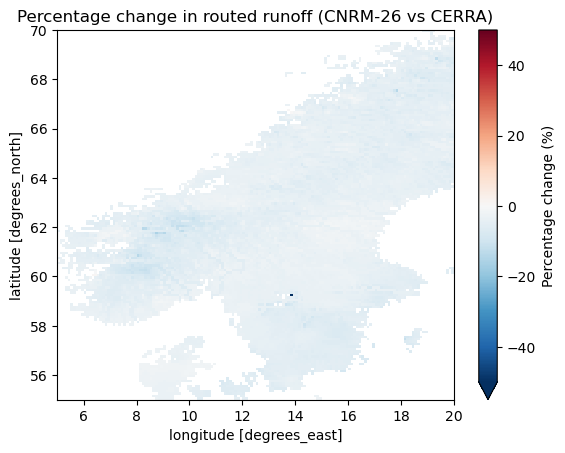

In [24]:
percentage_change = ((ds_routed_mean_map - ds_cerra_routed_mean_map) / ds_cerra_routed_mean_map * 100)
sel_extent(percentage_change, extent={"lat_min": 55, "lat_max": 70, "lon_min": 5, "lon_max": 20}).plot(cmap='RdBu_r', vmin=-50, vmax=50, cbar_kwargs={'label': 'Percentage change (%)'})
plt.title('Percentage change in routed runoff (CNRM-26 vs CERRA)')
plt.show()

In [ ]:
sel_extent(percentage_change, extent={"lat_min": 55, "lat_max": 70, "lon_min": 5, "lon_max": 20}).quantile(0.99)

<xarray.DataArray 'Qrouted' ()> Size: 8B
array(-2.5126255)
Coordinates:
    quantile  float64 8B 0.95

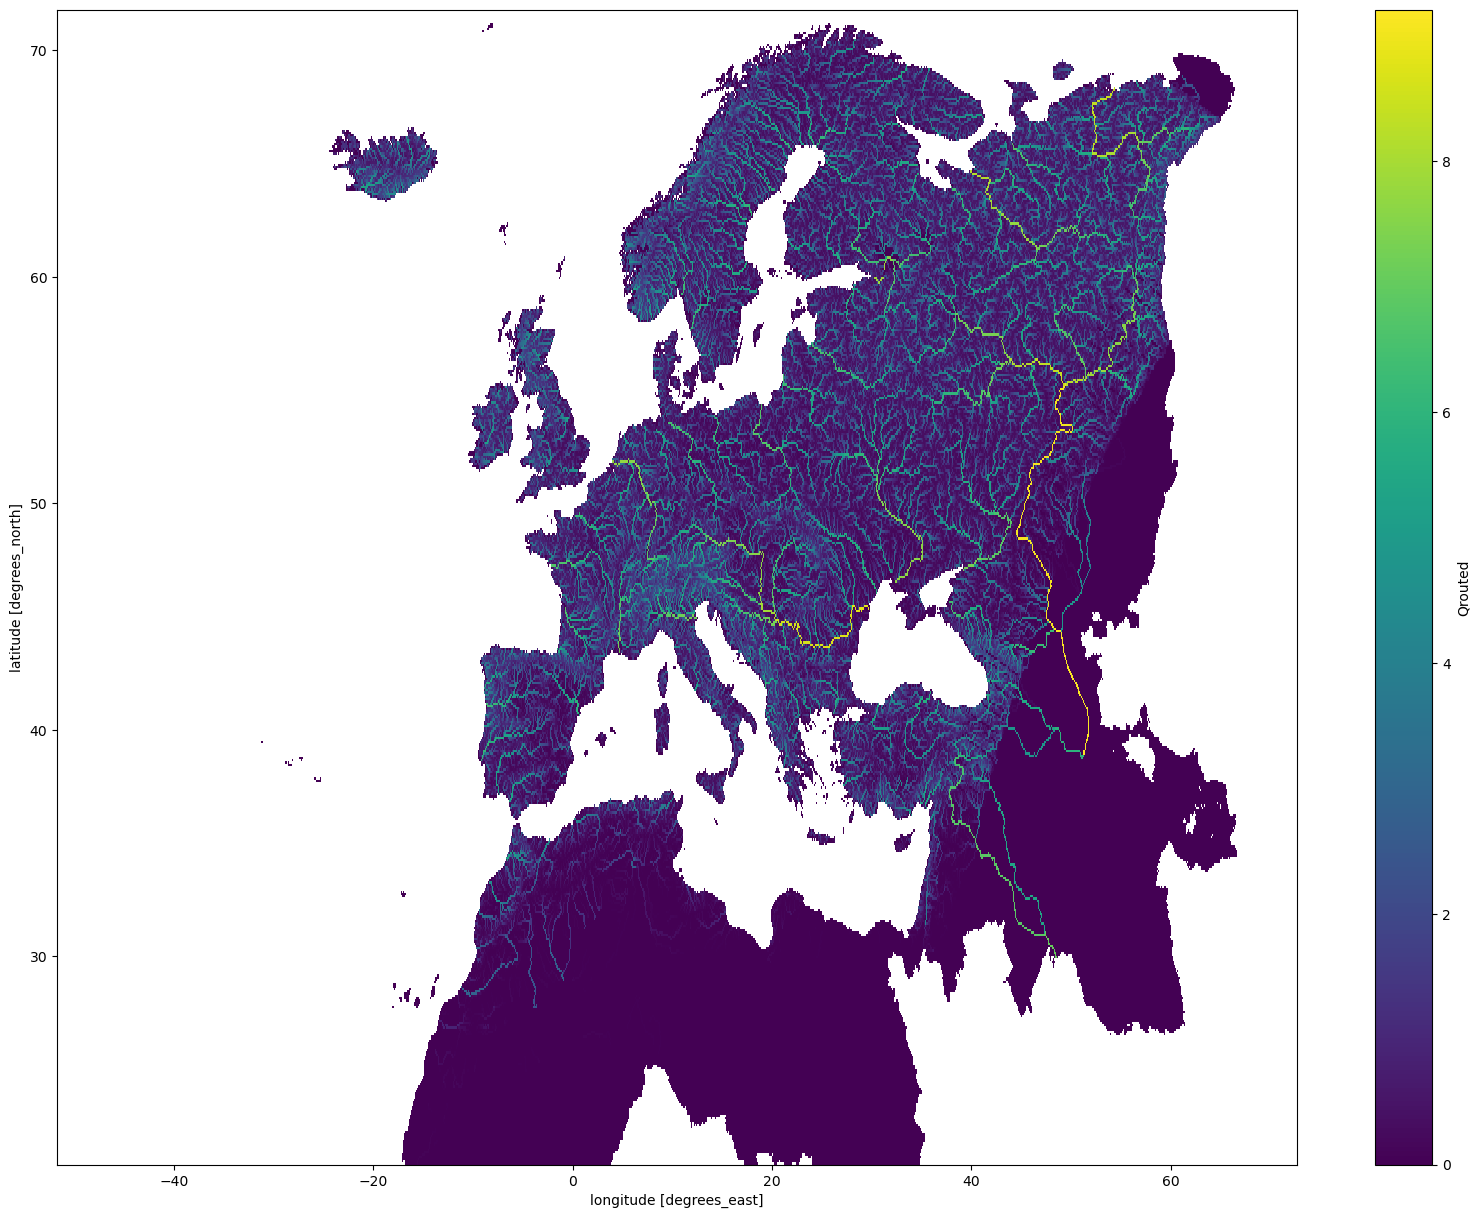

In [7]:
(np.log(ds_routed_mean_map+1)).plot(figsize=(20, 15))

In [8]:
path_routed_cmip6_runoff = Path("/net/land/landclim/pseubert/out/hist/")
folders = ["1995-1999", "2000-2004", "2005-2009", "2010-2014"]
list_ds_routed_cmip6 = []
for model in path_routed_cmip6_runoff.glob("*/"):
    list_q_routed_cmip6 = []
    for folder in model.glob("*/"):
        if folder.stem in folders:
            l = list(folder.glob("Qrouted*.zarr"))
            if len(l) > 0:
                list_q_routed_cmip6.append(str(l[0]))
    if len(list_q_routed_cmip6) == len(folders):
        print(f"Loading CMIP6 routed runoff for model {model.stem}")
        ds_routed_cmip6 = sel_extent(xr.open_mfdataset(list_q_routed_cmip6, chunks="auto", engine="zarr"),
                                    extent={"lat_min": EXTENT_CH["lat_min"], "lat_max": EXTENT_CH["lat_max"] + 2, "lon_min": EXTENT_CH["lon_min"], "lon_max": EXTENT_CH["lon_max"]}
                                    #  extent=EXTENT_CH
                                    )
        ds_routed_cmip6 = ds_routed_cmip6.assign_coords(model=[model.stem])
        ds_routed_cmip6 = ds_routed_cmip6.convert_calendar("standard", align_on="year")
        list_ds_routed_cmip6.append(ds_routed_cmip6)
ds_routed_cmip6_all = xr.concat(list_ds_routed_cmip6, dim="model")

Loading CMIP6 routed runoff for model BCC-CSM2-MR
Loading CMIP6 routed runoff for model CESM2
Loading CMIP6 routed runoff for model CMCC-CM2-SR5
Loading CMIP6 routed runoff for model CMCC-ESM2
Loading CMIP6 routed runoff for model CanESM5
Loading CMIP6 routed runoff for model EC-Earth3
Loading CMIP6 routed runoff for model GFDL-CM4
Loading CMIP6 routed runoff for model HadGEM3-GC31-LL
Loading CMIP6 routed runoff for model HadGEM3-GC31-MM
Loading CMIP6 routed runoff for model INM-CM4-8
Loading CMIP6 routed runoff for model INM-CM5-0
Loading CMIP6 routed runoff for model IPSL-CM6A-LR
Loading CMIP6 routed runoff for model KACE-1-0-G
Loading CMIP6 routed runoff for model MIROC-ES2L
Loading CMIP6 routed runoff for model MIROC6
Loading CMIP6 routed runoff for model MPI-ESM1-2-HR
Loading CMIP6 routed runoff for model MPI-ESM1-2-LR
Loading CMIP6 routed runoff for model MRI-ESM2-0
Loading CMIP6 routed runoff for model NorESM2-LM
Loading CMIP6 routed runoff for model UKESM1-0-LL


In [9]:
# Calculate grid cell area for 0.1° x 0.1° resolution
lat_mean = (EXTENT_CH["lat_min"] + EXTENT_CH["lat_max"]) / 2  # ~46.85°
deg_to_m_lat = 111320  # meters per degree latitude
deg_to_m_lon = 111320 * np.cos(np.radians(lat_mean))  # meters per degree longitude at mean latitude

area_m2 = (0.1 * deg_to_m_lat) * (0.1 * deg_to_m_lon)  # area in m²

ds_routed_mm_d = ds_routed.ds_data * 1000 * (3600 * 24) / area_m2  # from m3/s to mm/day

In [ ]:
path_cesm = Path("/net/xenon/climphys/lbloin/CESM2energy/output/bias_correction/A/historical/A/atmospheric_variables/")
ds_cesm_discharge = sel_extent(xr.open_mfdataset(
    sorted(path_cesm.glob("bced_CESM2_discharge*.nc")),
    chunks="auto"
), extent={"lat_min": EXTENT_CH["lat_min"], "lat_max": EXTENT_CH["lat_max"] + 2, "lon_min": EXTENT_CH["lon_min"], "lon_max": EXTENT_CH["lon_max"]})

In [ ]:
path_cerra = Path(path_data_processed / "cerra_processed" / "regridded" / "ro.zarr")
ds_cerra_runoff = sel_extent(xr.open_zarr(path_cerra, chunks="auto"), extent=EXTENT_CH)
ds_cerra_runoff_m3s = ds_cerra_runoff * area_m2 / 1000 / (3600 * 24)

In [ ]:
ds_era5_runoff = xr.open_dataset("/net/radon/climphys/FTP/lbloin/runoff_ERA5_1982-2022.nc")
ds_era5_runoff = sel_extent(ds_era5_runoff, extent={"lat_min": EXTENT_CH["lat_min"], "lat_max": EXTENT_CH["lat_max"] + 2, "lon_min": EXTENT_CH["lon_min"], "lon_max": EXTENT_CH["lon_max"]})

In [ ]:
# Compute area for each grid cell in ERA5 dataset (latitude-dependent)
# Get grid resolution
lat_diff = np.abs(np.diff(ds_era5_runoff.lat.values)).mean()
lon_diff = np.abs(np.diff(ds_era5_runoff.lon.values)).mean()

print(f"ERA5 grid resolution: {lat_diff}° lat x {lon_diff}° lon")

# Calculate area for each latitude
deg_to_m_lat = 111320  # meters per degree latitude
deg_to_m_lon = 111320 * np.cos(np.radians(ds_era5_runoff.lat))  # varies with latitude

# Area in m² for each grid cell (2D array: lat x lon)
area_era5_m2 = (lat_diff * deg_to_m_lat) * (lon_diff * deg_to_m_lon)

print(f"Area range: {area_era5_m2.min().values:.2f} - {area_era5_m2.max().values:.2f} m²")
print(f"Mean area: {area_era5_m2.mean().values:.2f} m²")

ERA5 grid resolution: 0.9424083769633332° lat x 1.25° lon
Area range: 9485254093.26 - 10021039675.85 m²
Mean area: 9754466524.63 m²


In [ ]:
# Convert ERA5 runoff from mm/day to m³/s using latitude-dependent area
ds_era5_runoff_m3s = ds_era5_runoff[["runoff"]] * area_era5_m2 / 1000 / (3600 * 24)

In [ ]:
ds_era5_discharge = xr.open_dataset("/net/xenon/climphys/lbloin/CESM2energy/output/bias_correction/Raw_ERA5_discharge.nc")
ds_era5_discharge = sel_extent(ds_era5_discharge, extent={"lat_min": EXTENT_CH["lat_min"], "lat_max": EXTENT_CH["lat_max"] + 2, "lon_min": EXTENT_CH["lon_min"], "lon_max": EXTENT_CH["lon_max"]})

# CNRM-CNRM rcp2.6

In [ ]:
with ProgressBar(dt=1):
    ds_cerra_runoff_weekly = ds_cerra_runoff_m3s["ro"].isel(lev=0).sum(dim=["lat", "lon"]).resample(time="7D").sum().compute()

[########################################] | 100% Completed | 5.00 ss


In [ ]:
with ProgressBar(dt=1):
    ds_routed_yearly = ds_routed.ds_data["Qrouted"].sum(dim=["lat", "lon"]).resample(time="YE").sum().compute()

[########################################] | 100% Completed | 198.17 s


In [ ]:
with ProgressBar(dt=1):
    ds_routed_weekly = ds_routed.ds_data["Qrouted"].sum(dim=["lat", "lon"]).resample(time="7D").sum().compute()

[########################################] | 100% Completed | 132.45 s


In [ ]:
with ProgressBar(dt=1):
    ds_cesm_discharge_weekly = ds_cesm_discharge.discharge.sum(dim=["lat", "lon"]).resample(time="7D").sum().compute()

[########################################] | 100% Completed | 2.00 ss


In [ ]:
with ProgressBar(dt=1):
    ds_routed_mm_d_yearly = ds_routed_mm_d.sum(dim=["lat", "lon"]).resample(time="YE").sum().compute()

[########################################] | 100% Completed | 114.14 s


In [ ]:
with ProgressBar(dt=1):
    ds_routed_cmip6_all_weekly = ds_routed_cmip6_all["Qrouted"].sum(dim=["lat", "lon"]).resample(time="7D").sum().compute()

[########################################] | 100% Completed | 29m 4ss


In [ ]:
with ProgressBar(dt=1):
    ds_runoff_m3s_weekly = ds_runoff_m3s.sum(dim=["lat", "lon"]).resample(time="7D").sum().compute()

[########################################] | 100% Completed | 8.04 ss


In [ ]:
ds_era5_runoff_m3s_weekly = ds_era5_runoff_m3s["runoff"].sum(dim=["lat", "lon"]).resample(time="7D").sum().compute()

In [ ]:
ds_era5_discharge_weekly = ds_era5_discharge.discharge.sum(dim=["lat", "lon"]).resample(time="7D").sum().compute()

In [ ]:
with ProgressBar(dt=1):
    ds_routed_mean_map = ds_routed.ds_data["Qrouted"].sel(time=slice("1995", "2014")).mean(dim="time").compute()
    ds_cesm_discharge_mean_map = ds_cesm_discharge.discharge.mean(dim="time").compute()
    ds_cerra_runoff_m3s_mean_map = ds_cerra_runoff_m3s.mean(dim="time").compute()
    ds_era5_discharge_mean_map = ds_era5_discharge.discharge.mean(dim="time").compute()

[########################################] | 100% Completed | 47.07 s
[########################################] | 100% Completed | 1.00 ss
[########################################] | 100% Completed | 1.00 ss


In [ ]:
with ProgressBar(dt=1):
    ds_routed_mean_map_june = ds_routed.ds_data["Qrouted"].sel(time=slice("1995", "2014")).sel(time=ds_routed.ds_data["Qrouted"].sel(time=slice("1995", "2014")).time.dt.month == 6).mean(dim="time").compute()

[########################################] | 100% Completed | 11.01 s


In [ ]:
with ProgressBar(dt=1):
    ds_cesm_routed_mean_map = ds_routed_cmip6_all.sel(model="CESM2").sel(time=slice("1995", "2014")).mean(dim="time").compute()

[########################################] | 100% Completed | 142.15 s


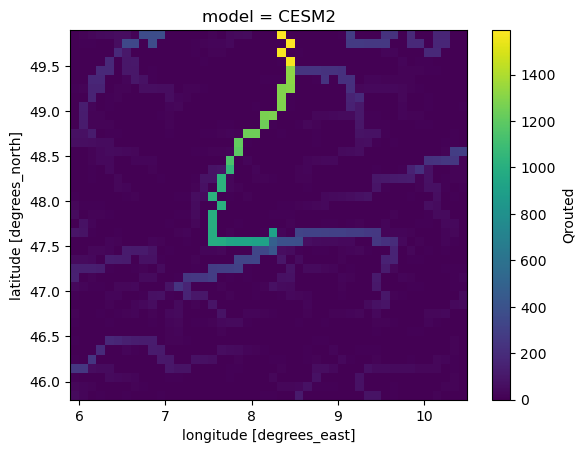

In [ ]:
ds_cesm_routed_mean_map["Qrouted"].plot()

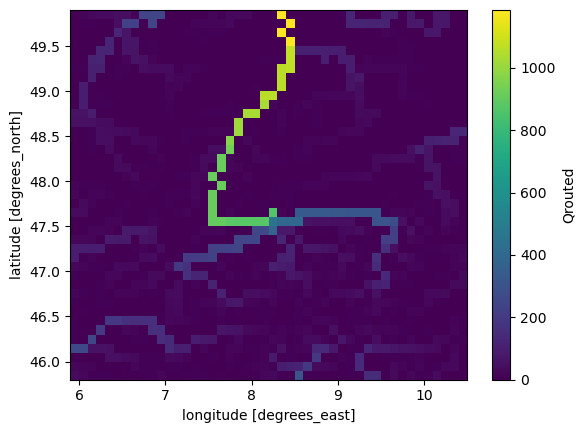

In [ ]:
ds_routed_mean_map.plot()

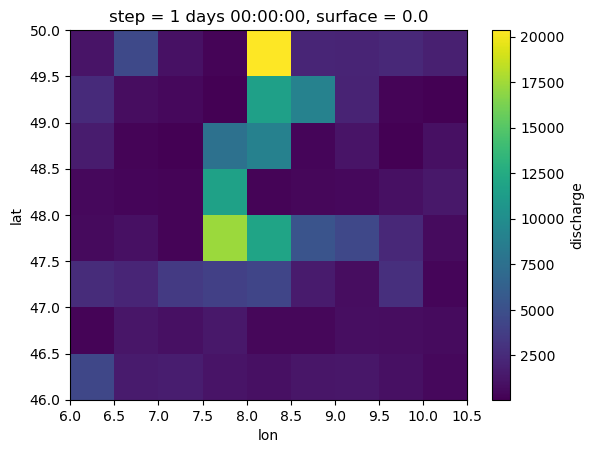

In [ ]:
ds_cesm_discharge_mean_map.plot()

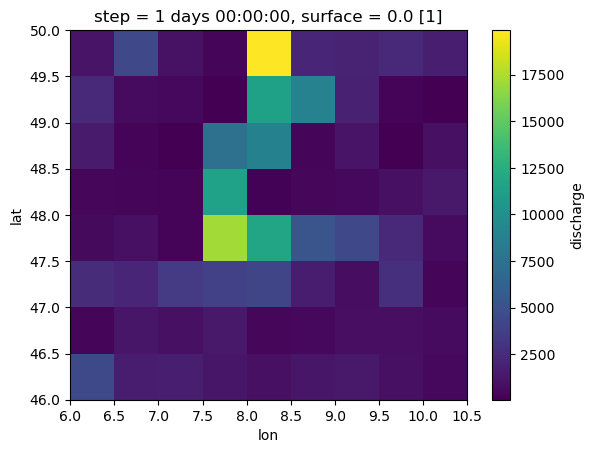

In [ ]:
ds_era5_discharge_mean_map.plot()

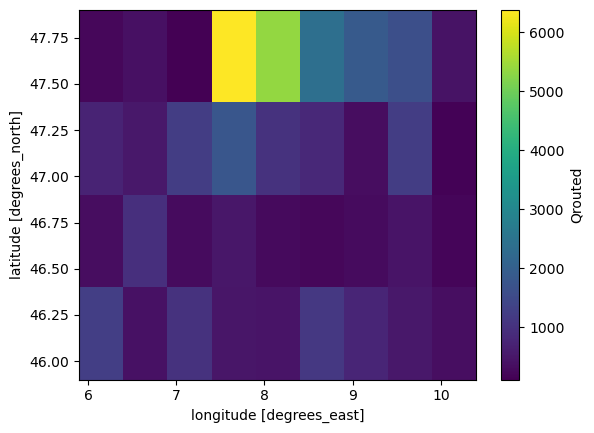

In [ ]:
ds_routed_mean_map.coarsen(dim={"lat": 5, "lon": 5}, boundary="trim").sum().plot()

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Plot RGS yearly
ds_routed_weekly.sel(time=slice("1995", "2014")).plot(ax=axes[0])
axes[0].set_xlabel("Week")
axes[0].set_ylabel("Weekly discharge ( m³/s)")
axes[0].set_title("Weekly Sum of Routed Runoff")
axes[0].grid(True, alpha=0.3)

# Plot routed runoff yearly
ds_cesm_discharge_weekly.plot(ax=axes[1])
axes[1].set_xlabel("Week")
axes[1].set_ylabel("Weekly discharge ( m³/s)")
axes[1].set_title("Weekly Sum of CESM Discharge")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
ds_routed_weekly.mean()

<xarray.DataArray 'Qrouted' ()> Size: 8B
array(275780.27761045)

In [ ]:
ds_cesm_discharge_weekly.mean()

<xarray.DataArray 'discharge' ()> Size: 8B
array(600411.83406389)
Coordinates:
    step     timedelta64[ns] 8B 1 days
    surface  float64 8B 0.0

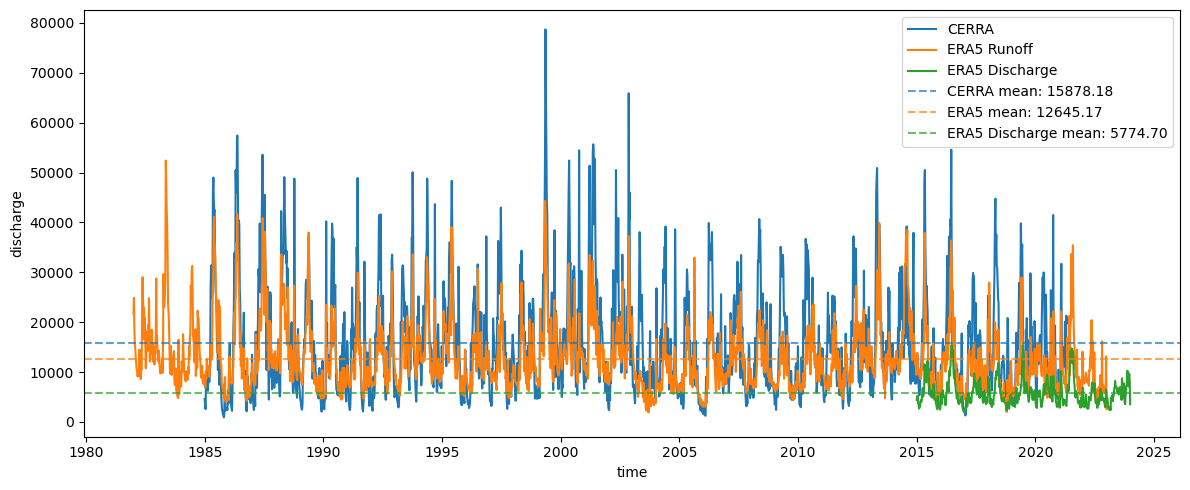

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ds_cerra_runoff_weekly.plot(ax=ax, label="CERRA")
ds_era5_runoff_m3s_weekly.plot(ax=ax, label="ERA5 Runoff")
ds_era5_discharge_weekly.plot(ax=ax, label="ERA5 Discharge")

# Add mean lines
cerra_mean = ds_cerra_runoff_weekly.mean().values
era5_mean = ds_era5_runoff_m3s_weekly.mean().values
era5_discharge_mean = ds_era5_discharge_weekly.mean().values

ax.axhline(y=cerra_mean, color='C0', linestyle='--', linewidth=1.5, alpha=0.7, label=f'CERRA mean: {cerra_mean:.2f}')
ax.axhline(y=era5_mean, color='C1', linestyle='--', linewidth=1.5, alpha=0.7, label=f'ERA5 mean: {era5_mean:.2f}')
ax.axhline(y=era5_discharge_mean, color='C2', linestyle='--', linewidth=1.5, alpha=0.7, label=f'ERA5 Discharge mean: {era5_discharge_mean:.2f}')

plt.legend()
plt.tight_layout()
plt.show()

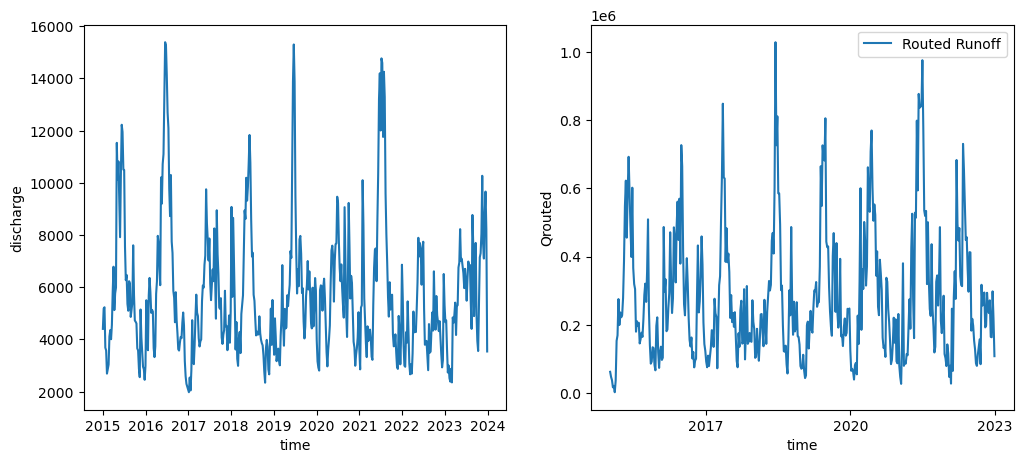

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ds_era5_discharge_weekly.plot(ax=axes[0], label="ERA5 Discharge")
ds_routed_weekly.sel(time=slice("2015", "2022")).plot(ax=axes[1], label="Routed Runoff")
plt.legend()
# plt.tight_layout()
plt.show()

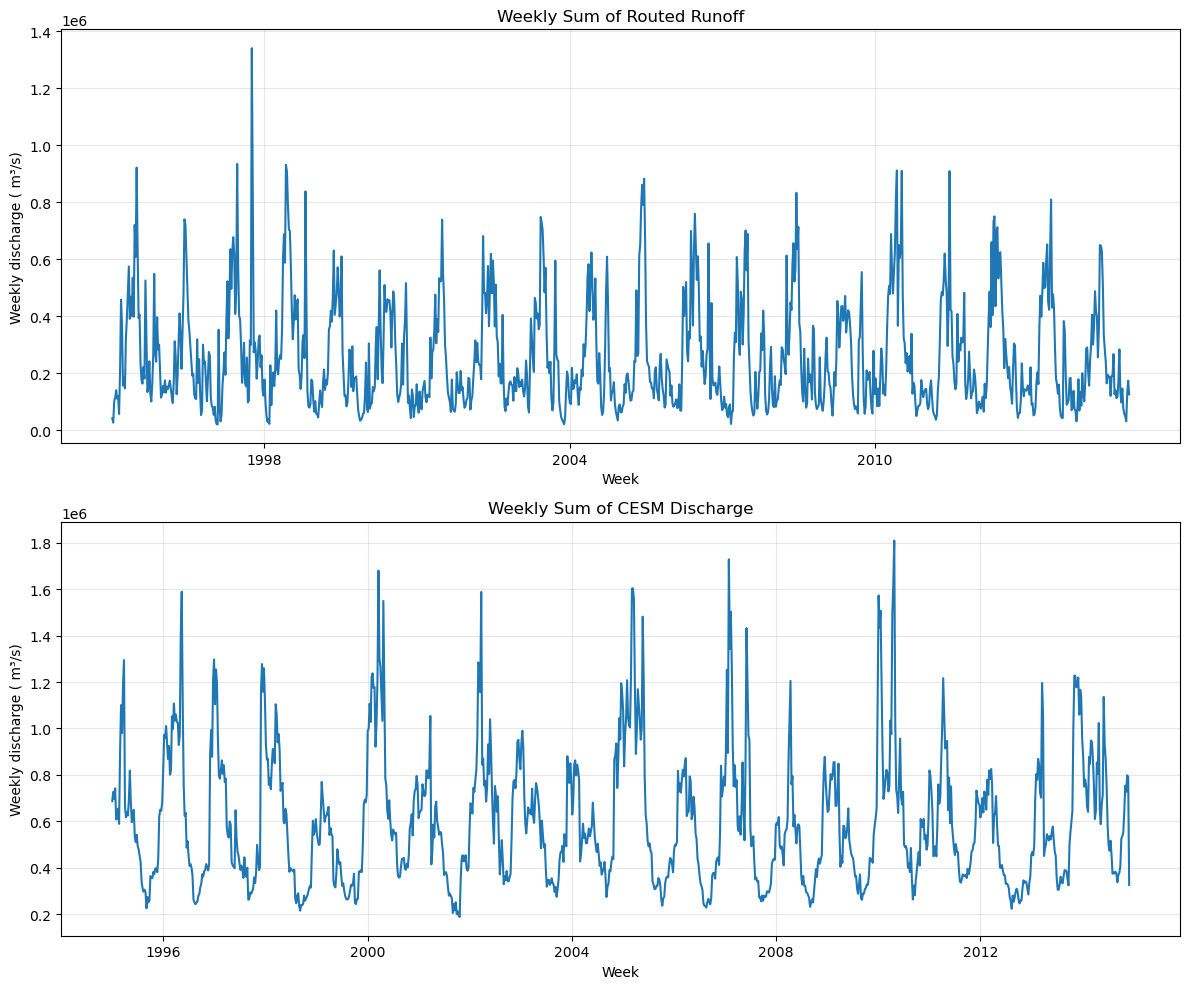

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Plot RGS yearly
ds_routed_weekly.sel(time=slice("1995", "2014")).plot(ax=axes[0])
axes[0].set_xlabel("Week")
axes[0].set_ylabel("Weekly discharge ( m³/s)")
axes[0].set_title("Weekly Sum of Routed Runoff")
axes[0].grid(True, alpha=0.3)

# Plot routed runoff yearly
ds_cesm_discharge_weekly.plot(ax=axes[1])
axes[1].set_xlabel("Week")
axes[1].set_ylabel("Weekly discharge ( m³/s)")
axes[1].set_title("Weekly Sum of CESM Discharge")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

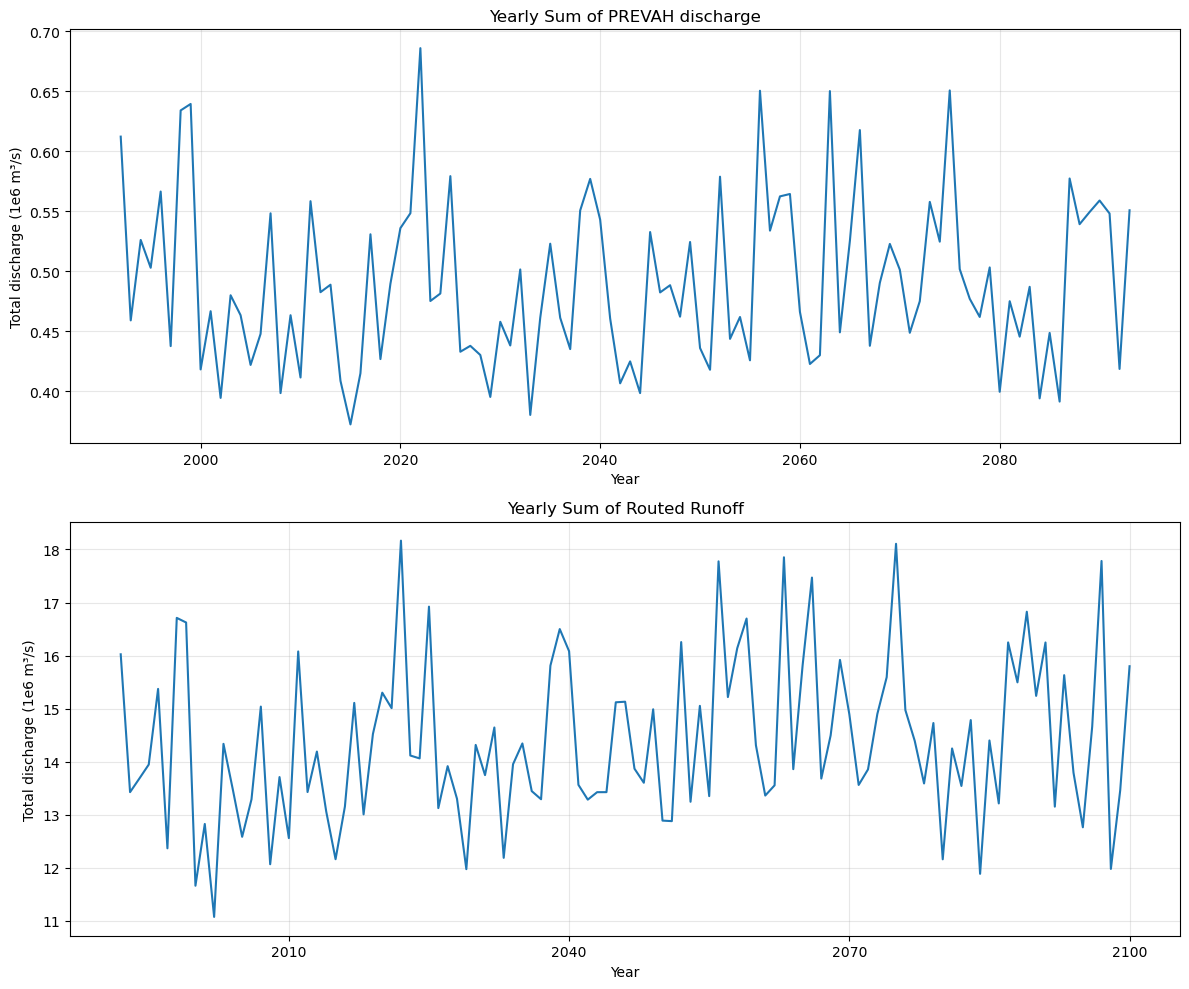

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Plot RGS yearly
(ds_rgs_m3s_yearly * 1e-6).plot(ax=axes[0])
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Total discharge (1e6 m³/s)")
axes[0].set_title("Yearly Sum of PREVAH discharge")
axes[0].grid(True, alpha=0.3)

# Plot routed runoff yearly
(ds_routed_yearly * 1e-6).plot(ax=axes[1])
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Total discharge (1e6 m³/s)")
axes[1].set_title("Yearly Sum of Routed Runoff")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

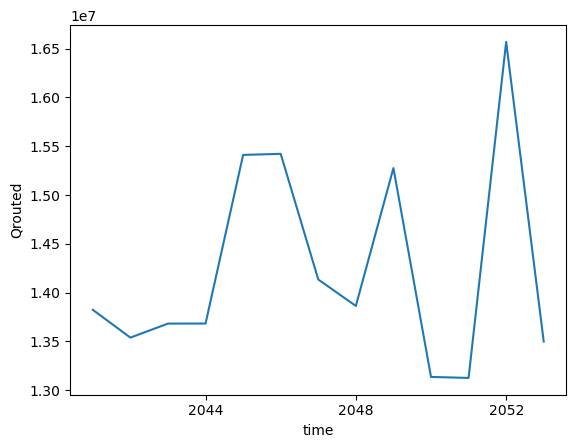

In [ ]:
ds_routed_mm_d_yearly["Qrouted"].sel(time=slice("2040", "2052")).plot()

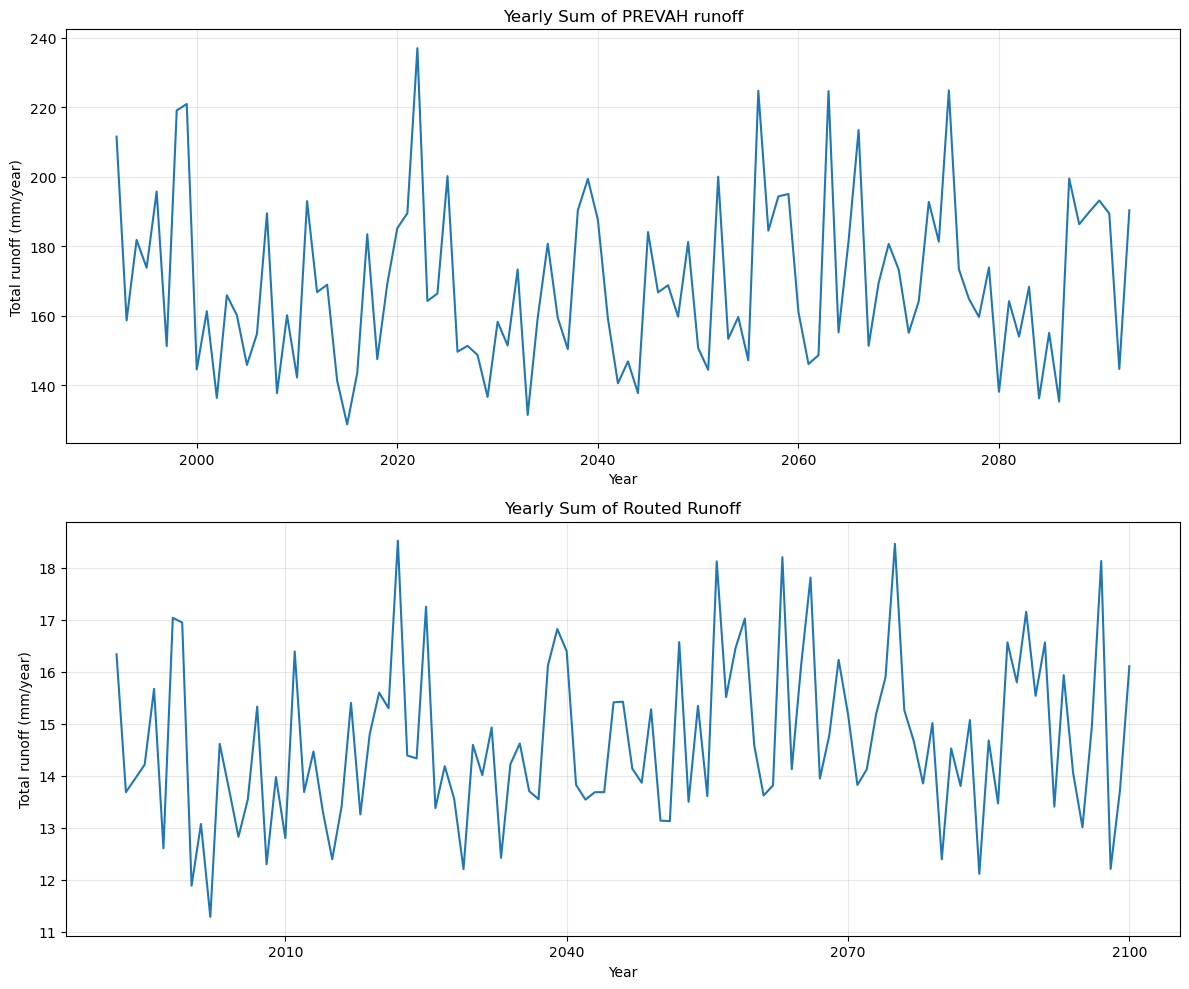

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Plot RGS yearly
(ds_rgs_yearly * 1e-6).plot(ax=axes[0])
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Total runoff (mm/year)")
axes[0].set_title("Yearly Sum of PREVAH runoff")
axes[0].grid(True, alpha=0.3)

# Plot routed runoff yearly
(ds_routed_mm_d_yearly["Qrouted"] * 1e-6).plot(ax=axes[1])
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Total runoff (mm/year)")
axes[1].set_title("Yearly Sum of Routed Runoff")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()